In [2]:
%pip install duckdb-engine --quiet

Note: you may need to restart the kernel to use updated packages.


In [3]:
import duckdb
import pandas as pd
from pathlib import Path

DATA = Path('/Users/wissamezzedine/Documents/Projects/SQL Projects/sql-airbnb-madrid/Data')

# Verify all 4 files exist before continuing
for name in ['listings', 'calendar', 'reviews', 'neighbourhoods']:
    p = DATA / f'{name}.csv'
    assert p.exists(), f"MISSING: {p}"
    print(f"  ✓ {name}.csv  ({p.stat().st_size / 1_000_000:.1f} MB)")

# Single DuckDB connection used for all queries in this notebook
con = duckdb.connect()

# Register each CSV as a queryable view
for name in ['listings', 'calendar', 'reviews', 'neighbourhoods']:
    con.execute(f"""
        CREATE OR REPLACE VIEW {name} AS
        SELECT * FROM read_csv_auto('{DATA / (name + ".csv")}', sample_size=-1)
    """)

print("\n4 views ready: listings, calendar, reviews, neighbourhoods")
print("Query with: con.sql('YOUR SQL').df()")

  ✓ listings.csv  (57.0 MB)
  ✓ calendar.csv  (296.9 MB)
  ✓ reviews.csv  (367.0 MB)
  ✓ neighbourhoods.csv  (0.0 MB)

4 views ready: listings, calendar, reviews, neighbourhoods
Query with: con.sql('YOUR SQL').df()


In [4]:
con.sql("""
    SELECT 'listings'        AS table_name, COUNT(*) AS row_count FROM listings
    UNION ALL SELECT 'calendar',                     COUNT(*) FROM calendar
    UNION ALL SELECT 'reviews',                      COUNT(*) FROM reviews
    UNION ALL SELECT 'neighbourhoods',               COUNT(*) FROM neighbourhoods
""").df()

,table_name,row_count
0,listings,23002
1,calendar,8395763
2,reviews,1329098
3,neighbourhoods,128


In [5]:
con.sql("DESCRIBE listings").df()

,column_name,column_type,null,key,default,extra
0,id,BIGINT,YES,None,None,None
1,listing_url,VARCHAR,YES,None,None,None
2,scrape_id,BIGINT,YES,None,None,None
3,last_scraped,DATE,YES,None,None,None
4,source,VARCHAR,YES,None,None,None
...,...,...,...,...,...,...
85,calculated_host_listings_count,BIGINT,YES,None,None,None
86,calculated_host_listings_count_entire_homes,BIGINT,YES,None,None,None
87,calculated_host_listings_count_private_rooms,BIGINT,YES,None,None,None
88,calculated_host_listings_count_shared_rooms,BIGINT,YES,None,None,None


In [6]:
con.sql("""
    SELECT 
        id, host_name, neighbourhood_cleansed, room_type, 
        price, number_of_reviews, review_scores_rating
    FROM listings
    LIMIT 5
""").df()

,id,host_name,neighbourhood_cleansed,room_type,price,number_of_reviews,review_scores_rating
0,21853,Abdel,Cármenes,Private room,$34.25,33,4.58
1,30320,Dana,Sol,Entire home/apt,$174.60,176,4.63
2,30959,Angela,Embajadores,Entire home/apt,None,8,4.38
3,40916,Dana,Universidad,Entire home/apt,$97.00,64,4.74
4,70059,Diana,Universidad,Entire home/apt,None,64,4.68


In [7]:
con.execute("""
    CREATE OR REPLACE VIEW listings_clean AS
    SELECT 
        *,
        TRY_CAST(REPLACE(REPLACE(price, '$', ''), ',', '') AS DOUBLE) AS price_num
    FROM listings
""")
print("listings_clean view created: price_num column added (NULL if uncleanable)")

listings_clean view created: price_num column added (NULL if uncleanable)


In [8]:
con.sql("""
    SELECT 
        COUNT(*)                                        AS total_listings,
        COUNT(DISTINCT host_id)                         AS unique_hosts,
        COUNT(DISTINCT neighbourhood_cleansed)          AS neighborhoods,
        ROUND(AVG(price_num), 2)                        AS avg_price_eur,
        ROUND(MEDIAN(price_num), 2)                     AS median_price_eur,
        ROUND(MIN(price_num), 2)                        AS min_price,
        ROUND(MAX(price_num), 2)                        AS max_price,
        COUNT(*) FILTER (WHERE price_num IS NULL)       AS listings_missing_price
    FROM listings_clean
""").df()

,total_listings,unique_hosts,neighborhoods,avg_price_eur,median_price_eur,min_price,max_price,listings_missing_price
0,23002,9593,128,179.28,133.5,3.38,36883.0,5309


In [9]:
con.sql("""
    SELECT 
        neighbourhood_cleansed                   AS neighborhood,
        COUNT(*)                                 AS listings,
        ROUND(AVG(price_num), 2)                 AS avg_price,
        ROUND(MEDIAN(price_num), 2)              AS median_price,
        ROUND(AVG(review_scores_rating), 2)     AS avg_rating
    FROM listings_clean
    WHERE price_num IS NOT NULL
    GROUP BY neighbourhood_cleansed
    ORDER BY listings DESC
    LIMIT 10
""").df()

,neighborhood,listings,avg_price,median_price,avg_rating
0,Embajadores,1843,189.65,137.67,4.62
1,Universidad,1536,229.08,149.50,4.63
2,Palacio,1380,210.58,157.93,4.69
3,Sol,1047,226.03,172.00,4.64
4,Justicia,896,208.70,162.88,4.64
5,Cortes,861,281.00,177.00,4.67
6,Cuatro Caminos,353,132.09,122.00,4.63
7,Trafalgar,342,178.97,154.00,4.65
8,Guindalera,300,164.92,137.50,4.58
9,Palos de Moguer,291,170.07,130.50,4.68


In [10]:
con.sql("""
    SELECT 
        room_type,
        COUNT(*)                                                          AS listings,
        ROUND(AVG(price_num), 2)                                          AS avg_price,
        ROUND(MEDIAN(price_num), 2)                                       AS median_price,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)                AS pct_of_market
    FROM listings_clean
    WHERE price_num IS NOT NULL
    GROUP BY room_type
    ORDER BY listings DESC
""").df()

,room_type,listings,avg_price,median_price,pct_of_market
0,Entire home/apt,12857,208.64,154.63,72.7
1,Private room,4677,102.52,68.00,26.4
2,Shared room,123,46.06,27.00,0.7
3,Hotel room,36,119.90,123.00,0.2


In [11]:
con.sql("""
    SELECT 
        host_id,
        host_name,
        COUNT(*)                        AS num_listings,
        ROUND(AVG(price_num), 2)        AS avg_price
    FROM listings_clean
    WHERE price_num IS NOT NULL
    GROUP BY host_id, host_name
    ORDER BY num_listings DESC
    LIMIT 10
""").df()

,host_id,host_name,num_listings,avg_price
0,346367515,Ukio,338,156.26
1,438136382,Homeclub,324,160.15
2,377605855,MIT House,274,250.56
3,518713670,Bemadrid,240,73.49
4,661816734,Felipe,215,21.57
5,40877988,⁨Raul Sanchez V.⁩,155,235.91
6,133056146,Dobo Homes,121,123.76
7,444912851,Duke Host,119,110.30
8,567327895,Match4room,116,50.19
9,107141654,Leeways,104,166.29


In [12]:
con.sql("""
    WITH host_sizes AS (
        SELECT 
            host_id,
            COUNT(*) AS num_listings
        FROM listings_clean
        GROUP BY host_id
    )
    SELECT 
        CASE 
            WHEN num_listings = 1                  THEN '1 listing'
            WHEN num_listings = 2                  THEN '2 listings'
            WHEN num_listings BETWEEN 3 AND 5      THEN '3-5 listings'
            WHEN num_listings BETWEEN 6 AND 10     THEN '6-10 listings'
            WHEN num_listings BETWEEN 11 AND 50    THEN '11-50 listings'
            ELSE                                        '50+ listings'
        END                                                                  AS portfolio_size,
        COUNT(*)                                                             AS hosts,
        SUM(num_listings)                                                    AS total_listings,
        ROUND(100.0 * SUM(num_listings) / SUM(SUM(num_listings)) OVER (), 1) AS pct_of_market
    FROM host_sizes
    GROUP BY portfolio_size
    ORDER BY MIN(num_listings)
""").df()

,portfolio_size,hosts,total_listings,pct_of_market
0,1 listing,7024,7024.0,30.5
1,2 listings,1133,2266.0,9.9
2,3-5 listings,872,3215.0,14.0
3,6-10 listings,319,2335.0,10.2
4,11-50 listings,213,4250.0,18.5
5,50+ listings,32,3912.0,17.0


In [13]:
con.sql("""
    WITH host_sizes AS (
        SELECT 
            host_id,
            COUNT(*)                                          AS num_listings,
            NTILE(10) OVER (ORDER BY COUNT(*) DESC)           AS decile
        FROM listings_clean
        GROUP BY host_id
    )
    SELECT 
        decile,
        COUNT(*)                                                            AS hosts_in_decile,
        SUM(num_listings)                                                   AS listings_controlled,
        ROUND(100.0 * SUM(num_listings) / SUM(SUM(num_listings)) OVER (), 1) AS pct_of_all_listings,
        MIN(num_listings)                                                   AS min_in_decile,
        MAX(num_listings)                                                   AS max_in_decile
    FROM host_sizes
    GROUP BY decile
    ORDER BY decile
""").df()

,decile,hosts_in_decile,listings_controlled,pct_of_all_listings,min_in_decile,max_in_decile
0,1,960,12255.0,53.3,4,388
1,2,960,2425.0,10.5,2,4
2,3,960,1609.0,7.0,1,2
3,4,959,959.0,4.2,1,1
4,5,959,959.0,4.2,1,1
5,6,959,959.0,4.2,1,1
6,7,959,959.0,4.2,1,1
7,8,959,959.0,4.2,1,1
8,9,959,959.0,4.2,1,1
9,10,959,959.0,4.2,1,1


In [14]:
con.sql("""
    WITH host_class AS (
        SELECT 
            host_id,
            CASE WHEN COUNT(*) = 1 THEN 'Single-listing host' 
                 ELSE 'Multi-listing host' END                AS host_type
        FROM listings_clean
        GROUP BY host_id
    )
    SELECT 
        hc.host_type,
        COUNT(*)                                              AS listings,
        ROUND(AVG(l.price_num), 2)                            AS avg_price,
        ROUND(MEDIAN(l.price_num), 2)                         AS median_price,
        ROUND(AVG(l.review_scores_rating), 2)                 AS avg_rating,
        ROUND(AVG(l.availability_365), 1)                     AS avg_availability_days
    FROM listings_clean l
    JOIN host_class hc ON l.host_id = hc.host_id
    WHERE l.price_num IS NOT NULL
    GROUP BY hc.host_type
    ORDER BY listings DESC
""").df()

,host_type,listings,avg_price,median_price,avg_rating,avg_availability_days
0,Multi-listing host,13612,177.56,134.59,4.61,222.2
1,Single-listing host,4081,185.01,128.50,4.74,194.9


In [16]:
con.sql("DESCRIBE calendar").df()

,column_name,column_type,null,key,default,extra
0,listing_id,BIGINT,YES,None,None,None
1,date,DATE,YES,None,None,None
2,available,BOOLEAN,YES,None,None,None
3,minimum_nights,BIGINT,YES,None,None,None
4,maximum_nights,BIGINT,YES,None,None,None


In [17]:
con.sql("SELECT * FROM calendar LIMIT 5").df()

,listing_id,date,available,minimum_nights,maximum_nights
0,13667341,2026-03-26,False,2,9
1,13667341,2026-03-27,False,2,9
2,13667341,2026-03-28,False,2,9
3,13667341,2026-03-29,False,2,9
4,13667341,2026-03-30,False,2,9


In [18]:
con.sql("""
    WITH booked AS (
        SELECT 
            listing_id,
            COUNT(*) FILTER (WHERE available = FALSE) AS booked_nights,
            COUNT(*)                                  AS total_nights
        FROM calendar
        GROUP BY listing_id
    )
    SELECT 
        b.listing_id,
        l.neighbourhood_cleansed                            AS neighborhood,
        l.room_type,
        l.price_num                                         AS list_price,
        b.booked_nights,
        b.total_nights,
        ROUND(100.0 * b.booked_nights / b.total_nights, 1)  AS occupancy_pct,
        ROUND(b.booked_nights * l.price_num, 0)             AS est_annual_revenue_eur
    FROM booked b
    JOIN listings_clean l ON b.listing_id = l.id
    WHERE l.price_num IS NOT NULL
      AND l.price_num BETWEEN 20 AND 1000   -- strip obvious price outliers
    ORDER BY est_annual_revenue_eur DESC
    LIMIT 15
""").df()

,listing_id,neighborhood,room_type,list_price,booked_nights,total_nights,occupancy_pct,est_annual_revenue_eur
0,922195037478492127,Piovera,Entire home/apt,913.00,352,365,96.4,321376.0
1,553848657601583119,Universidad,Entire home/apt,903.00,355,365,97.3,320565.0
2,760841936602728403,Casco Histórico de Vallecas,Entire home/apt,984.50,301,365,82.5,296335.0
3,804194462844113360,Bellas Vistas,Private room,1000.00,275,365,75.3,275000.0
4,1116187365835841909,Palacio,Entire home/apt,909.00,288,365,78.9,261792.0
5,17243915,Sol,Entire home/apt,862.00,303,365,83.0,261186.0
6,50069926,Embajadores,Entire home/apt,741.83,341,365,93.4,252964.0
7,34620489,El Goloso,Private room,913.00,277,365,75.9,252901.0
8,1172960962030755579,Cortes,Entire home/apt,780.00,324,365,88.8,252720.0
9,597466756900958850,Goya,Entire home/apt,922.00,273,365,74.8,251706.0


In [19]:
con.sql("""
    WITH booked AS (
        SELECT 
            listing_id,
            COUNT(*) FILTER (WHERE available = FALSE) AS booked_nights
        FROM calendar
        GROUP BY listing_id
    ),
    listing_revenue AS (
        SELECT 
            l.neighbourhood_cleansed                       AS neighborhood,
            l.id                                           AS listing_id,
            b.booked_nights * l.price_num                  AS est_annual_revenue,
            b.booked_nights
        FROM listings_clean l
        JOIN booked b ON l.id = b.listing_id
        WHERE l.price_num IS NOT NULL
          AND l.price_num BETWEEN 20 AND 1000
    )
    SELECT 
        neighborhood,
        COUNT(*)                                                AS listings,
        ROUND(AVG(booked_nights), 0)                            AS avg_booked_nights,
        ROUND(AVG(est_annual_revenue), 0)                       AS avg_revenue_per_listing,
        ROUND(SUM(est_annual_revenue), 0)                       AS total_neighborhood_revenue,
        RANK() OVER (ORDER BY AVG(est_annual_revenue) DESC)     AS revenue_per_listing_rank
    FROM listing_revenue
    GROUP BY neighborhood
    HAVING COUNT(*) >= 50
    ORDER BY avg_revenue_per_listing DESC
    LIMIT 15
""").df()

,neighborhood,listings,avg_booked_nights,avg_revenue_per_listing,total_neighborhood_revenue,revenue_per_listing_rank
0,Recoletos,240,156.0,40410.0,9698352.0,1
1,Goya,255,163.0,36796.0,9382963.0,2
2,Castellana,136,152.0,32646.0,4439886.0,3
3,Cortes,842,154.0,32623.0,27468787.0,4
4,Justicia,883,167.0,31219.0,27566489.0,5
5,Palacio,1367,162.0,31056.0,42453312.0,6
6,Sol,1034,159.0,31005.0,32058930.0,7
7,Niño Jesús,50,157.0,28176.0,1408793.0,8
8,Lista,154,145.0,28027.0,4316232.0,9
9,Jerónimos,72,126.0,27907.0,2009338.0,10


In [20]:
# Add Plotly + style constants for charts
import plotly.express as px
import plotly.graph_objects as go

ACCENT  = "#2DD4BF"
INDIGO  = "#818CF8"
PURPLE  = "#A78BFA"
WARNING = "#FB7185"
SUCCESS = "#34D399"
TEXT    = "#E8ECF1"

CHART_LAYOUT = dict(
    plot_bgcolor='rgba(0,0,0,0)',
    paper_bgcolor='rgba(0,0,0,0)',
    font=dict(family="sans-serif", color="#1f2937", size=12),
    xaxis=dict(gridcolor='rgba(0,0,0,0.06)'),
    yaxis=dict(gridcolor='rgba(0,0,0,0.06)'),
    margin=dict(l=20, r=20, t=50, b=40),
    title_font=dict(size=16),
)

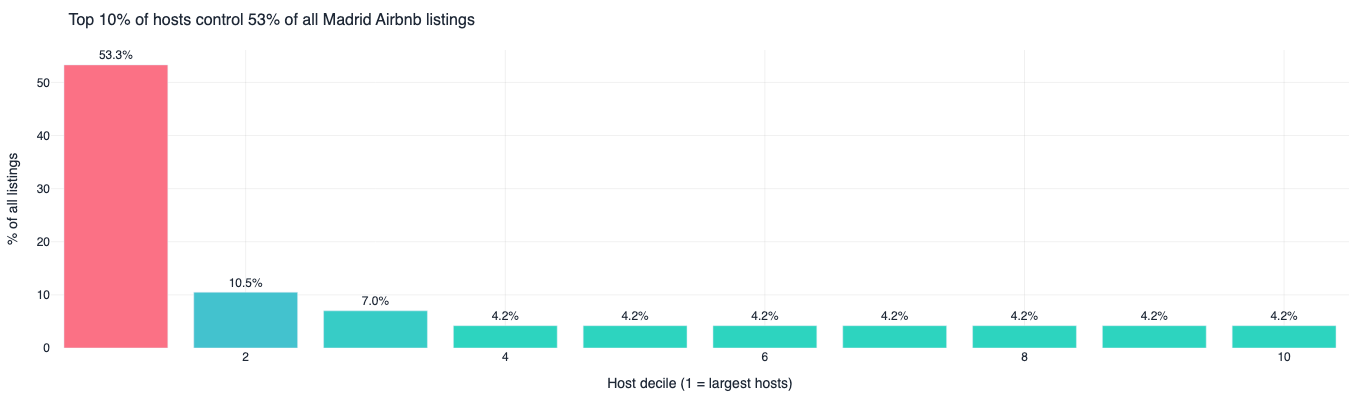

In [21]:
decile_df = con.sql("""
    WITH host_sizes AS (
        SELECT host_id, COUNT(*) AS num_listings,
               NTILE(10) OVER (ORDER BY COUNT(*) DESC) AS decile
        FROM listings_clean GROUP BY host_id
    )
    SELECT 
        decile,
        ROUND(100.0 * SUM(num_listings) / SUM(SUM(num_listings)) OVER (), 1) AS pct_of_market
    FROM host_sizes
    GROUP BY decile
    ORDER BY decile
""").df()

fig1 = px.bar(
    decile_df, x='decile', y='pct_of_market',
    text='pct_of_market',
    title='Top 10% of hosts control 53% of all Madrid Airbnb listings',
    labels={'decile': 'Host decile (1 = largest hosts)', 'pct_of_market': '% of all listings'},
    color='pct_of_market',
    color_continuous_scale=[ACCENT, INDIGO, WARNING],
)
fig1.update_traces(texttemplate='%{text:.1f}%', textposition='outside')
fig1.update_layout(showlegend=False, coloraxis_showscale=False, **CHART_LAYOUT, height=400)
fig1.show()

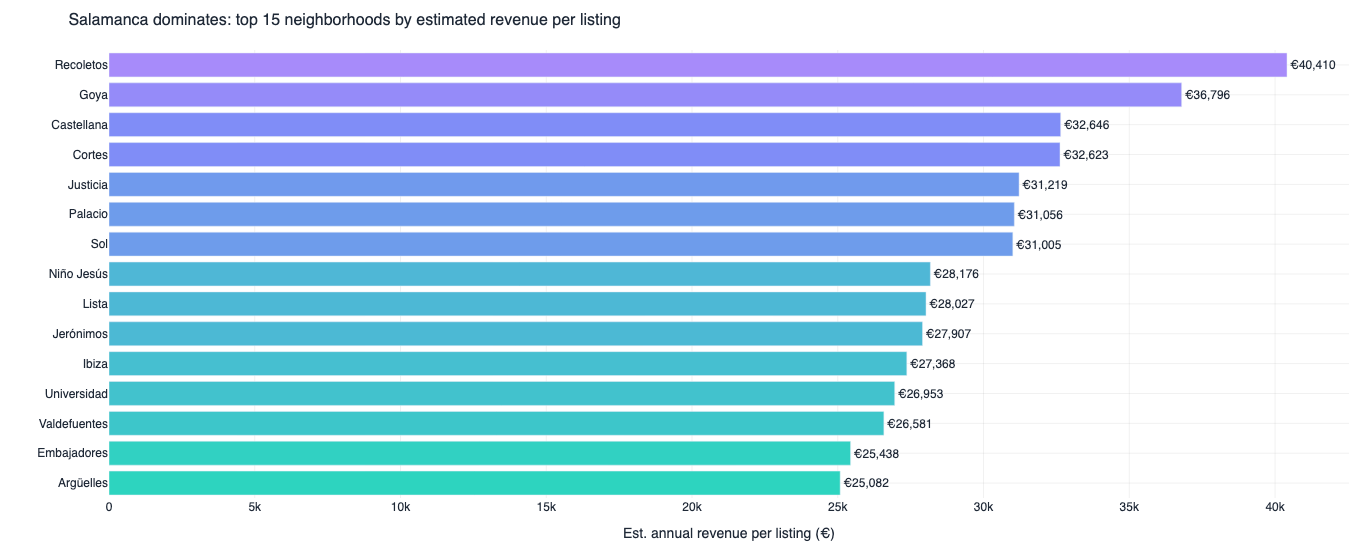

In [22]:
lucrative_df = con.sql("""
    WITH booked AS (
        SELECT listing_id, COUNT(*) FILTER (WHERE available = FALSE) AS booked_nights
        FROM calendar GROUP BY listing_id
    ),
    listing_revenue AS (
        SELECT l.neighbourhood_cleansed AS neighborhood, b.booked_nights * l.price_num AS rev
        FROM listings_clean l JOIN booked b ON l.id = b.listing_id
        WHERE l.price_num BETWEEN 20 AND 1000
    )
    SELECT neighborhood, ROUND(AVG(rev), 0) AS avg_revenue_per_listing
    FROM listing_revenue
    GROUP BY neighborhood
    HAVING COUNT(*) >= 50
    ORDER BY avg_revenue_per_listing DESC LIMIT 15
""").df().sort_values('avg_revenue_per_listing')

fig2 = px.bar(
    lucrative_df, x='avg_revenue_per_listing', y='neighborhood', orientation='h',
    text='avg_revenue_per_listing',
    title='Salamanca dominates: top 15 neighborhoods by estimated revenue per listing',
    labels={'avg_revenue_per_listing': 'Est. annual revenue per listing (€)', 'neighborhood': ''},
    color='avg_revenue_per_listing',
    color_continuous_scale=[ACCENT, INDIGO, PURPLE],
)
fig2.update_traces(texttemplate='€%{text:,.0f}', textposition='outside')
fig2.update_layout(showlegend=False, coloraxis_showscale=False, **CHART_LAYOUT, height=550)
fig2.show()

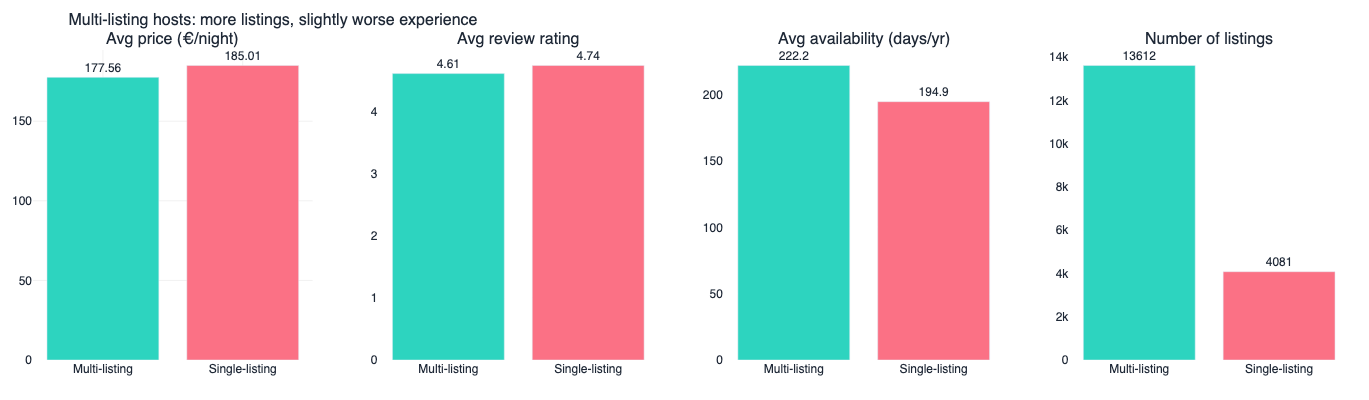

In [23]:
comparison_df = con.sql("""
    WITH host_class AS (
        SELECT host_id,
               CASE WHEN COUNT(*) = 1 THEN 'Single-listing' ELSE 'Multi-listing' END AS host_type
        FROM listings_clean GROUP BY host_id
    )
    SELECT hc.host_type,
           ROUND(AVG(l.price_num), 2)                        AS avg_price,
           ROUND(AVG(l.review_scores_rating), 2)             AS avg_rating,
           ROUND(AVG(l.availability_365), 1)                 AS avg_availability_days,
           COUNT(*)                                          AS listings
    FROM listings_clean l JOIN host_class hc ON l.host_id = hc.host_id
    WHERE l.price_num IS NOT NULL
    GROUP BY hc.host_type
""").df()

# Build a 4-panel comparison
metrics = [
    ('avg_price',             'Avg price (€/night)'),
    ('avg_rating',            'Avg review rating'),
    ('avg_availability_days', 'Avg availability (days/yr)'),
    ('listings',              'Number of listings'),
]
from plotly.subplots import make_subplots
fig3 = make_subplots(rows=1, cols=4, subplot_titles=[m[1] for m in metrics])
for i, (col, label) in enumerate(metrics, start=1):
    fig3.add_trace(go.Bar(
        x=comparison_df['host_type'], y=comparison_df[col],
        marker_color=[ACCENT, WARNING],
        text=comparison_df[col],
        texttemplate='%{text}', textposition='outside',
        showlegend=False,
    ), row=1, col=i)
fig3.update_layout(
    title='Multi-listing hosts: more listings, slightly worse experience',
    height=400, **CHART_LAYOUT,
)
fig3.show()

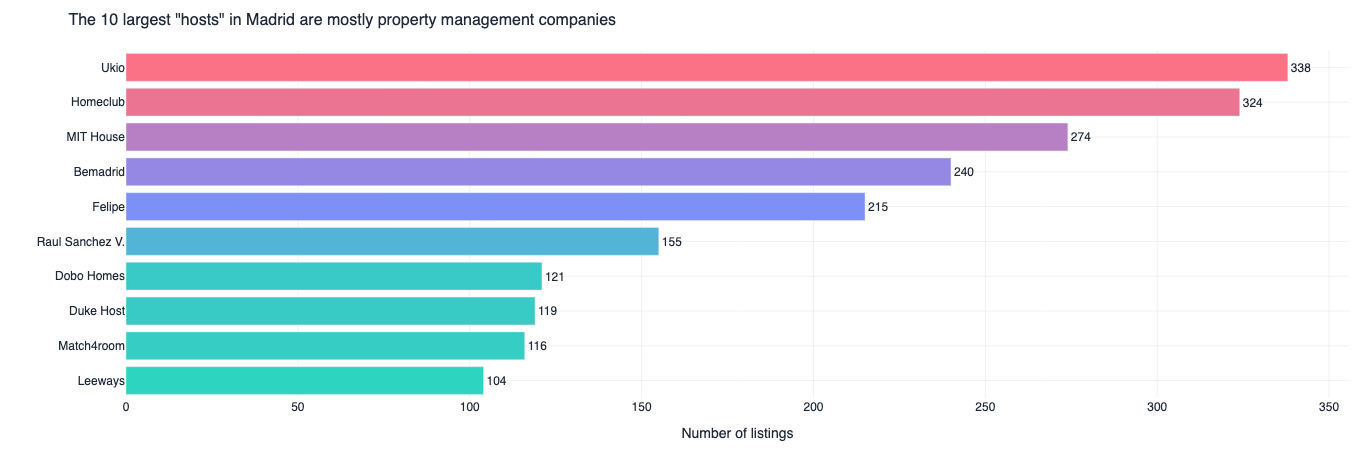

In [24]:
top_hosts_df = con.sql("""
    SELECT 
        host_name,
        host_id,
        COUNT(*)                       AS num_listings,
        ROUND(AVG(price_num), 2)       AS avg_price
    FROM listings_clean
    WHERE price_num IS NOT NULL AND host_name IS NOT NULL
    GROUP BY host_name, host_id
    ORDER BY num_listings DESC
    LIMIT 10
""").df().sort_values('num_listings')

fig4 = px.bar(
    top_hosts_df,
    x='num_listings', y='host_name', orientation='h',
    text='num_listings',
    title='The 10 largest "hosts" in Madrid are mostly property management companies',
    labels={'num_listings': 'Number of listings', 'host_name': ''},
    color='num_listings',
    color_continuous_scale=[ACCENT, INDIGO, WARNING],
    hover_data={'avg_price': ':,.2f'},
)
fig4.update_traces(texttemplate='%{text}', textposition='outside')
fig4.update_layout(showlegend=False, coloraxis_showscale=False, **CHART_LAYOUT, height=450)
fig4.show()